# Two-group ROI analysis: learners (non-Mandarin) vs. native listeners (Mandarin)

Reads the per-ROI tables written by `extract_roi_values.py` (both groups, all contrasts, one first-level model: `scrubbed-splitfb`) and runs the analyses in `09_integration/TWO_GROUP_MANUSCRIPT_PLAN.md` (R2–R4). The statistics live in `group_stats.py`; this notebook is the sequence of calls plus figures.

**Before trusting anything here:** the learners' rows must reproduce `group_level_all_ROI.ipynb` (section 1b below).

Contrasts:
- `sound`: vs. baseline, both groups (`resp` is in the model as a nuisance regressor but not reported: it follows the sound by <1 s, too close to separate at TR = 3 s)
- `fbcorrect`: correct feedback vs. baseline, both groups -- the feedback contrast for group comparisons
- `fbcorrectvswrong`: learners only (natives get ~1 wrong-feedback trial per run, so it's missing or unreliable for them)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import group_stats as gs

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)

nilearn_dir = '/ix1/bchandrasekaran/krs228/data/FLT/data_denoised/derivatives/nilearn'
group_dir = os.path.join(nilearn_dir, 'group_space-T1w_fwhm-0.00')
roi_dir = os.path.join(group_dir, 'roi-values_scrubbed-splitfb')
out_dir = os.path.join(group_dir, 'stats_two-group')
os.makedirs(out_dir, exist_ok=True)

# resampling settings, matching robustness_checks.py
n_perms, n_boot, seed = 10000, 10000, 0

## 1. Load and check

In [2]:
df = gs.load_roi_values(roi_dir)
print(df.groupby('participant_group').participant_id.nunique())
gs.coverage(df)

participant_group
Mandarin        13
non-Mandarin    12
Name: participant_id, dtype: int64


learning_stage                      early  middle  final
contrast         participant_group                      
fbcorrect        Mandarin              13      13     13
                 non-Mandarin          12      12     12
fbcorrectvswrong Mandarin               6       3      1
                 non-Mandarin          12      12     12
sound            Mandarin              13      13     13
                 non-Mandarin          12      12     12

Inputs `extract_roi_values.py` couldn't find. Expected: Mandarin participants' `fbcorrectvswrong` in stages where a run had no wrong trials. Anything else needs a look.

In [3]:
missing_fpath = os.path.join(roi_dir, 'roi-values_missing.tsv')
try:
    missing = pd.read_csv(missing_fpath, sep='\t')
except pd.errors.EmptyDataError:   # nothing was missing
    missing = pd.DataFrame()
missing

,participant_id,kind,stage,contrast,path
0,sub-FLT03,stat_map,early,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
1,sub-FLT03,stat_map,middle,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
2,sub-FLT03,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
3,sub-FLT05,stat_map,middle,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
4,sub-FLT05,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
5,sub-FLT08,stat_map,early,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
6,sub-FLT08,stat_map,middle,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
7,sub-FLT08,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
8,sub-FLT10,stat_map,early,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...
9,sub-FLT10,stat_map,final,fbcorrectvswrong,/ix1/bchandrasekaran/krs228/data/FLT/data_deno...


### 1b. Learners' rows match `group_level_all_ROI.ipynb`'s tables

`group_level_all_ROI.ipynb` now reads its ROI values from the same `extract_roi_values.py` tables, so this is only a consistency check (max difference should be exactly 0). It was the real cross-check while that notebook still masked the maps itself: the two methods agreed exactly on 2026-11-04 (REVISION_PLAN #32). IFGo/IFGt are dropped here, so the PFC row counts are lower.

In [4]:
checks = []
for network in gs.NETWORKS:
    for contrast in ['sound', 'fbcorrectvswrong']:
        nb_fpath = os.path.join(group_dir, f'univariate-results_network-{network}_contrast-{contrast}.tsv')
        if not os.path.exists(nb_fpath):
            continue
        nb_df = pd.read_csv(nb_fpath, sep='\t')
        mine = df[(df.network == network) & (df.contrast == contrast) & (df.participant_group == 'non-Mandarin')]
        merged = mine.merge(nb_df, on=['participant_id', 'region_hemi', 'learning_stage'], suffixes=('', '_nb'))
        checks.append({'network': network, 'contrast': contrast, 'rows_matched': len(merged),
                       'rows_here': len(mine), 'max_abs_diff': (merged.beta - merged.beta_nb).abs().max()})
pd.DataFrame(checks)

,network,contrast,rows_matched,rows_here,max_abs_diff
0,tian-S2,sound,432,432,4.440892e-16
1,tian-S2,fbcorrectvswrong,432,432,0.000000e+00
2,auditory,sound,504,504,4.440892e-16
3,auditory,fbcorrectvswrong,504,504,0.000000e+00
4,pfc,sound,648,648,4.440892e-16
5,pfc,fbcorrectvswrong,648,648,4.440892e-16


## 2. Responses vs. baseline within each group

Stages averaged, hemispheres averaged; FDR across regions within each group × contrast × network.

In [5]:
baseline = gs.baseline_tests(df)
baseline.to_csv(os.path.join(out_dir, 'baseline_by_group.tsv'), sep='\t', index=False)

(baseline[baseline.contrast.isin(['sound', 'fbcorrect'])]
 .assign(result=lambda d: d.t.round(2).astype(str) + np.where(d.q < .05, '*', ''))
 .pivot_table(index=['network', 'region'], columns=['contrast', 'participant_group'], values='result', aggfunc='first'))

contrast           fbcorrect                 sound             
participant_group   Mandarin non-Mandarin Mandarin non-Mandarin
network  region                                                
auditory HG             -2.3       -6.15*    7.12*        6.27*
         PP            -2.56       -4.96*    5.65*        4.65*
         PT            -2.82       -3.33*    10.2*        7.49*
         ParsOp         0.88         0.76    2.78*         2.13
         ParsTri        0.23         1.39    -1.27        -1.57
         STGa           0.63        -0.38    7.18*         5.1*
         STGp          -0.42         -0.3    9.47*        8.21*
pfc      ACC           -0.48        -0.02     -0.5        -0.94
         FMC            1.48        -0.84     2.35        -3.1*
         FO            -0.57        -0.17     3.8*        3.84*
         FP            -0.23        -0.09   -2.97*       -6.64*
         MFG           -0.94         0.84    -0.09        -0.21
         OFC           -0.17         0.47    -0.54       -4.39*
         PCG           -0.24         0.64    -0.39         -1.8
         PreCG         -0.16        -1.36    5.85*        6.68*
         SFG             0.4         1.21      0.8        -0.27
tian-S2  NAc-core       0.73         0.18    2.62*        3.93*
         NAc-shell      1.76        -1.97    2.86*         1.28
         aCAU          -0.93          0.2     1.02        3.54*
         aPUT          4.23*        3.23*    7.05*        6.96*
         pCAU           0.23         0.34    -0.02         1.67
         pPUT           1.57         1.52    3.62*         1.83

## 3. Does `fbcorrect` stand in for `fbcorrectvswrong` in learners?

The group comparison of feedback has to use `fbcorrect`. It's only a fair stand-in if, in learners, it shows the same learning-stage trend as the headline `fbcorrectvswrong` effect (plan R3). If it doesn't, section 4's feedback result needs reframing before it's interpreted.

In [6]:
trends = gs.subject_trends(df)
trends.to_csv(os.path.join(out_dir, 'subject_trends.tsv'), sep='\t', index=False)

pd.concat([gs.learner_contrast_agreement(trends, region) for region in ['aCAU', 'aPUT']]).round(3)

,contrast,n,mean_trend,t,p,r,region,group
0,fbcorrectvswrong,12,-0.594,-3.297,0.007,NaN,aCAU,non-Mandarin
1,fbcorrect,12,-0.330,-1.908,0.083,NaN,aCAU,non-Mandarin
2,correlation between the two,12,NaN,NaN,0.445,0.244,aCAU,non-Mandarin
0,fbcorrectvswrong,12,0.017,0.083,0.935,NaN,aPUT,non-Mandarin
1,fbcorrect,12,0.065,0.447,0.664,NaN,aPUT,non-Mandarin
2,correlation between the two,12,NaN,NaN,0.297,0.329,aPUT,non-Mandarin


## 4. Planned test: is the aCAU feedback decline learner-specific?

Per-subject learning-stage trend (`[-1, 0, 1]`, final − early), within each group and learners − natives: Welch t, group-label permutation, leave-one-out, bootstrap CI. Then the same for the aCAU − aPUT differential trend.

In [7]:
planned = pd.concat([
    gs.trend_group_difference(trends, 'fbcorrect', 'aCAU', n_perms=n_perms, n_boot=n_boot, seed=seed),
    gs.trend_group_difference(gs.differential_trend(trends, 'fbcorrect', 'aCAU', 'aPUT'),
                              'fbcorrect', 'aCAU-minus-aPUT', n_perms=n_perms, n_boot=n_boot, seed=seed),
], ignore_index=True)
planned.to_csv(os.path.join(out_dir, 'planned_trend_group_tests.tsv'), sep='\t', index=False)
planned.round(4)

,test,n,estimate,t,p,permutation_p,loso_preserved,ci_lower,ci_upper,contrast,region
0,non-Mandarin trend vs 0,12,-0.3297,-1.9076,0.0829,0.0840,1/12,-0.6411,0.0112,fbcorrect,aCAU
1,Mandarin trend vs 0,13,0.0729,0.3920,0.7019,0.7283,0/13,-0.2540,0.4483,fbcorrect,aCAU
2,non-Mandarin - Mandarin (Welch),25,-0.4025,-1.5861,0.1264,0.1298,1/25,-0.8652,0.0840,fbcorrect,aCAU
3,non-Mandarin trend vs 0,12,-0.3949,-2.1782,0.0520,0.0542,3/12,-0.7326,-0.0547,fbcorrect,aCAU-minus-aPUT
4,Mandarin trend vs 0,13,0.2700,1.4077,0.1846,0.1877,0/13,-0.0817,0.6354,fbcorrect,aCAU-minus-aPUT
5,non-Mandarin - Mandarin (Welch),25,-0.6649,-2.5192,0.0192,0.0179,25/25,-1.1525,-0.1733,fbcorrect,aCAU-minus-aPUT


## 5. Group × stage, every region

Mixed ANOVA per region (stage within, group between), FDR per contrast × effect across all regions. Exploratory beyond the planned test in section 4.

In [8]:
anova = gs.group_by_stage_anova(df, contrasts=['sound', 'fbcorrect'])
anova.to_csv(os.path.join(out_dir, 'group_by_stage_anova.tsv'), sep='\t', index=False)
anova[anova.q < .05].sort_values(['contrast', 'effect', 'q']).round(4)

,network,contrast,region,effect,F,df1,df2,p,np2,n_per_group,q
72,pfc,sound,FMC,group,13.0173,1,23,0.0015,0.3614,"{'Mandarin': 13, 'non-Mandarin': 12}",0.0326


## 5b. Group differences per ROI

Learners − natives, Welch t with Cohen's d and a group-label permutation p, FDR across regions within each contrast × network (× stage). Exploratory, like section 5. `fbcorrectvswrong` is left out because natives mostly lack it.

First with stages averaged per participant (ignoring stage), then separately for each stage. Cells show t, with * for q < .05. Positive t means learners > natives.

In [9]:
group_diff = gs.group_difference_tests(df, n_perms=n_perms, seed=seed)
group_diff.to_csv(os.path.join(out_dir, 'group_difference_stage-avg.tsv'), sep='\t', index=False)

(group_diff
 .assign(result=lambda d: d.t.round(2).astype(str) + np.where(d.q < .05, '*', ''))
 .pivot_table(index=['network', 'region'], columns='contrast', values='result', aggfunc='first'))

contrast           fbcorrect   sound
network  region                     
auditory HG            -0.15   -1.76
         PP             0.32   -1.11
         PT            -0.82   -0.52
         ParsOp        -0.04    0.52
         ParsTri         0.8   -0.45
         STGa          -0.72   -0.62
         STGp           0.16  -3.12*
pfc      ACC            0.34   -0.44
         FMC           -1.67  -3.67*
         FO             0.36    -0.1
         FP             0.05   -1.93
         MFG            1.21   -0.07
         OFC            0.45   -2.68
         PCG            0.57   -1.19
         PreCG         -0.51    -0.2
         SFG            0.45    -0.8
tian-S2  NAc-core      -0.41    0.61
         NAc-shell     -2.62   -1.11
         aCAU           0.76     1.4
         aPUT           0.28    0.39
         pCAU           0.15    1.04
         pPUT           -0.7   -1.18

In [10]:
group_diff[group_diff.p < .05].sort_values(['contrast', 'p']).round(4)

,network,contrast,region,n_non-Mandarin,n_Mandarin,mean_non-Mandarin,mean_Mandarin,difference,t,p,d,permutation_p,q
33,tian-S2,fbcorrect,NAc-shell,12,13,-0.2173,0.1340,-0.3513,-2.6211,0.0164,-1.0634,0.0114,0.0986
24,pfc,sound,FMC,12,13,-0.3488,0.4007,-0.7495,-3.6723,0.0015,-1.4443,0.0013,0.0131
13,auditory,sound,STGp,12,13,3.1312,5.2272,-2.0960,-3.1246,0.0051,-1.2307,0.0061,0.0359
28,pfc,sound,OFC,12,13,-1.0032,-0.1257,-0.8775,-2.6815,0.0133,-1.0706,0.0093,0.0600


In [11]:
group_diff_stage = gs.group_difference_tests(df, by_stage=True, n_perms=n_perms, seed=seed)
group_diff_stage.to_csv(os.path.join(out_dir, 'group_difference_by-stage.tsv'), sep='\t', index=False)

(group_diff_stage
 .assign(result=lambda d: d.t.round(2).astype(str) + np.where(d.q < .05, '*', ''),
         learning_stage=lambda d: pd.Categorical(d.learning_stage, gs.STAGE_ORDER, ordered=True))
 .pivot_table(index=['network', 'region'], columns=['contrast', 'learning_stage'], values='result',
              aggfunc='first', observed=True))

contrast           fbcorrect                sound              
learning_stage         early middle  final  early middle  final
network  region                                                
auditory HG             0.87   0.15  -1.08  -0.16  -1.21  -1.89
         PP             0.54  -0.22   0.24   0.49  -0.92  -1.32
         PT             1.36  -1.02  -0.99    0.6  -0.43  -0.84
         ParsOp         1.09   1.21  -2.02   0.56   2.26  -1.51
         ParsTri        2.15   1.12  -2.41    0.9   0.17  -1.52
         STGa           2.18  -1.51  -1.29   0.65   0.06  -1.78
         STGp           1.06   -0.3  -0.26  -2.76  -1.61  -2.29
pfc      ACC            0.92   0.08  -0.17  -0.18   -0.8   0.16
         FMC           -0.85  -0.59  -1.23   -2.6  -1.66  -1.39
         FO             1.78   0.33  -0.86   0.98  -0.12  -1.15
         FP             0.92   0.87  -1.59   0.06  -0.37  -2.37
         MFG            1.43    2.7  -1.36   0.32   1.85   -1.8
         OFC            1.34   0.25  -1.03  -0.74  -2.08  -2.18
         PCG             0.9   1.55  -1.14  -0.22  -0.97  -1.12
         PreCG          0.81  -1.57   0.07   0.25  -0.07  -0.57
         SFG            0.93   3.04  -1.76   0.39   -0.4  -2.02
tian-S2  NAc-core      -0.07    0.8  -1.29   0.81   0.87  -0.28
         NAc-shell     -1.54  -1.51  -1.03  -0.97  -0.14  -1.26
         aCAU            1.4   0.62  -0.41   0.83   1.24   1.21
         aPUT          -0.46  -0.04   0.69   0.22   0.23   0.31
         pCAU          -0.15   1.15  -0.78   0.49    2.1  -0.34
         pPUT          -1.34   -1.5   0.93  -0.28  -1.11  -1.34

In [12]:
# sensitivity: FLT15 is Mandarin in participants.tsv but absent from the behavior
# summary (TWO_GROUP_MANUSCRIPT_PLAN.md, Sample) -- do the stage-averaged results hold without them?
group_diff_no15 = gs.group_difference_tests(df[df.participant_id != 'sub-FLT15'], n_perms=0)
(group_diff[['network', 'contrast', 'region', 't', 'q']]
 .merge(group_diff_no15[['network', 'contrast', 'region', 't', 'q']], on=['network', 'contrast', 'region'],
        suffixes=('', '_without_FLT15'))
 .query('q < .05 or q_without_FLT15 < .05').round(4))

,network,contrast,region,t,q,t_without_FLT15,q_without_FLT15
13,auditory,sound,STGp,-3.1246,0.0359,-2.8018,0.0787
24,pfc,sound,FMC,-3.6723,0.0131,-3.4497,0.0254


## 6. Figure: stage profiles by group

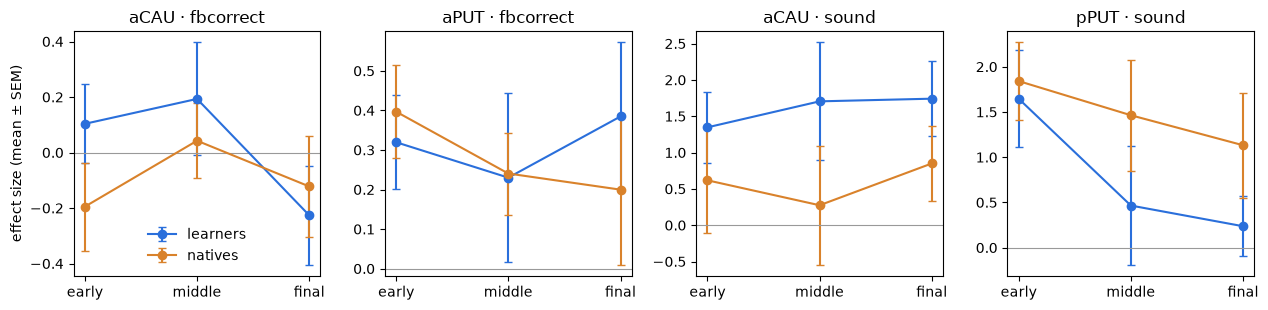

In [13]:
bilat = gs.bilateral_mean(df)
panels = [('fbcorrect', 'aCAU'), ('fbcorrect', 'aPUT'), ('sound', 'aCAU'), ('sound', 'pPUT')]
colors = {'non-Mandarin': '#2a6fdb', 'Mandarin': '#d9822b'}

fig, axes = plt.subplots(1, len(panels), figsize=(3.2 * len(panels), 3.2), sharey=False)
for ax, (contrast, region) in zip(axes, panels):
    sub = bilat[(bilat.contrast == contrast) & (bilat.region == region)]
    for group in gs.GROUPS:
        g = sub[sub.participant_group == group].groupby('learning_stage').beta
        mean, sem = g.mean().reindex(gs.STAGE_ORDER), g.sem().reindex(gs.STAGE_ORDER)
        ax.errorbar(range(3), mean, yerr=sem, marker='o', capsize=3, color=colors[group],
                    label='learners' if group == 'non-Mandarin' else 'natives')
    ax.axhline(0, color='0.6', lw=0.8)
    ax.set_xticks(range(3), gs.STAGE_ORDER)
    ax.set_title(f'{region} · {contrast}')
axes[0].set_ylabel('effect size (mean ± SEM)')
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(out_dir, 'stage_profiles_by_group.png'), dpi=300)

## 7. Learners only: headline `fbcorrectvswrong`

For reference alongside section 4; values match `robustness_summary.csv`.

In [14]:
learners = trends[trends.participant_group == 'non-Mandarin']
rows = []
for label, values in [('aCAU', learners.query("contrast == 'fbcorrectvswrong' and region == 'aCAU'").trend),
                      ('aCAU-minus-aPUT', gs.differential_trend(trends, 'fbcorrectvswrong', 'aCAU', 'aPUT')
                                            .query("participant_group == 'non-Mandarin'").trend)]:
    loso = gs.leave_one_out_stability(values)
    rows.append({'trend': label, 'n': len(values), 'mean': values.mean(),
                 't': loso['original_t'], 'p': loso['original_p'],
                 'exact_permutation_p': gs.exact_sign_flip_permutation_test(values)['p_value'],
                 'loso_preserved': f"{loso['n_preserved']}/{loso['n_folds']}"})
pd.DataFrame(rows).round(4)

,trend,n,mean,t,p,exact_permutation_p,loso_preserved
0,aCAU,12,-0.5935,-3.2971,0.0071,0.0073,12/12
1,aCAU-minus-aPUT,12,-0.6107,-2.9001,0.0144,0.0166,12/12
